# PHÂN TÍCH DỮ LIỆU PHẢN HỒI CỦA SINH VIÊN
**Khám phá và phân tích dữ liệu (Exploratory Data Analysis – EDA)**

## 1. Giới thiệu đề tài

Đề tài tập trung khám phá bộ dữ liệu phản hồi của sinh viên nhằm tìm hiểu cấu trúc dữ liệu, chất lượng dữ liệu và đặc điểm phân bố của các nhãn cảm xúc. Kết quả EDA là cơ sở để lựa chọn phương pháp tiền xử lý văn bản và xây dựng mô hình phân loại cảm xúc ở các phần tiếp theo.

## 2. Mục tiêu

- Tìm hiểu kích thước, cấu trúc và ý nghĩa các thuộc tính trong bộ dữ liệu.
- Kiểm tra dữ liệu thiếu, dữ liệu trùng lặp và tính hợp lệ của nhãn.
- Khảo sát nội dung phản hồi và sự phân bố các nhãn cảm xúc.
- Phân tích dữ liệu theo một số thuộc tính như khoa và loại phản hồi.
- Trực quan hóa các đặc điểm chính bằng biểu đồ.

## 3. Phạm vi phân tích

Biến mục tiêu dự kiến là `sentiment_label`, gồm các nhãn cảm xúc của phản hồi. Hai cột văn bản `feedback_text` và `preprocessed_text` được sử dụng để khảo sát nội dung. Các cột còn lại được xem xét nhằm hiểu thêm bối cảnh của phản hồi.

> Lưu ý: EDA chỉ mô tả dữ liệu hiện có. Không tự ý sửa nhãn cảm xúc hoặc loại bỏ dữ liệu nếu chưa có căn cứ rõ ràng. Những vấn đề về chất lượng dữ liệu cần được ghi nhận để thảo luận trong báo cáo.

## 4. Cài đặt và import thư viện

Sử dụng Pandas để đọc và thống kê dữ liệu; NumPy hỗ trợ tính toán; Matplotlib và Seaborn dùng để trực quan hóa.

In [1]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Đã import thư viện thành công!")

Đã import thư viện thành công!


## 5. Đọc dữ liệu

Notebook được thiết kế để chạy khi thư mục làm việc là thư mục dự án hoặc thư mục `notebooks`. Đoạn mã dưới đây tự tìm file trong thư mục `data` ở hai vị trí thường dùng.

In [2]:
# Tìm file dữ liệu theo cấu trúc dự án
possible_paths = [
    Path("../data/student_feedback_dataset.csv"),
    Path("data/student_feedback_dataset.csv"),
    Path("student_feedback_dataset.csv"),
]

DATA_PATH = next((p.resolve() for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy student_feedback_dataset.csv. "
        "Hãy đặt file trong thư mục data của dự án hoặc cùng thư mục với Notebook."
    )

df = pd.read_csv(DATA_PATH)

print("Đọc dữ liệu thành công!")
print("Đường dẫn dữ liệu:", DATA_PATH)
print("Kích thước dữ liệu:", df.shape)

display(df.head())

Đọc dữ liệu thành công!
Đường dẫn dữ liệu: D:\Nhap Mon Hoc May\BTL\data\student_feedback_dataset.csv
Kích thước dữ liệu: (1223, 11)


,student_id,department,subject_name,feedback_text,preprocessed_text,sentiment_label,sarcasm_flag,emotion_tag,feedback_type,subject_specific_context,response_required
0,STU0001,CIVIL,Concrete Tech,Attack medical dog technology top several insi...,attack medical dog technology top several insi...,negative,0,anger,Infrastructure,Project-Based,1
1,STU0002,CIVIL,Concrete Tech,Wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...,positive,0,anger,Infrastructure,Lab-Intensive,0
2,STU0003,BIO,Genetics,Bank those report box your treatment accept in...,bank those report box your treatment accept in...,neutral,0,sadness,Academic,Project-Based,1
3,STU0004,ME,Fluid Mechanics,Can character million listen right amount ask ...,can character million listen right amount ask ...,positive,0,joy,Academic,Theory-Heavy,0
4,STU0005,ME,Fluid Mechanics,Good cost political street dream finish figure.,good cost political street dream finish figure,negative,0,surprise,Academic,Theory-Heavy,1


## 6. Khám phá cấu trúc dữ liệu

### 6.1. Kích thước và danh sách thuộc tính

Kiểm tra số lượng bản ghi, số lượng thuộc tính và tên các cột trong bộ dữ liệu.

In [3]:
print(f"Số dòng: {df.shape[0]:,}")
print(f"Số cột: {df.shape[1]:,}")

print("\nDanh sách các cột:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Số dòng: 1,223
Số cột: 11

Danh sách các cột:
1. student_id
2. department
3. subject_name
4. feedback_text
5. preprocessed_text
6. sentiment_label
7. sarcasm_flag
8. emotion_tag
9. feedback_type
10. subject_specific_context
11. response_required


### 6.2. Kiểu dữ liệu và thống kê mô tả

`info()` cho biết kiểu dữ liệu và số giá trị không bị thiếu ở từng cột. Bảng thống kê mô tả giúp xem nhanh đặc điểm của các thuộc tính.

In [4]:
df.info()

display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 1223 entries, 0 to 1222
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   student_id                1223 non-null   str  
 1   department                1223 non-null   str  
 2   subject_name              1223 non-null   str  
 3   feedback_text             1223 non-null   str  
 4   preprocessed_text         1223 non-null   str  
 5   sentiment_label           1223 non-null   str  
 6   sarcasm_flag              1223 non-null   int64
 7   emotion_tag               1223 non-null   str  
 8   feedback_type             1223 non-null   str  
 9   subject_specific_context  1223 non-null   str  
 10  response_required         1223 non-null   int64
dtypes: int64(2), str(9)
memory usage: 105.2 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,1223,1223,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,1223,7,ECE,187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subject_name,1223,15,Embedded Systems,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
feedback_text,1223,1223,Attack medical dog technology top several insi...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
preprocessed_text,1223,1223,attack medical dog technology top several insi...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sentiment_label,1223,3,positive,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sarcasm_flag,1223.0,NaN,NaN,NaN,0.134096,0.340895,0.0,0.0,0.0,0.0,1.0
emotion_tag,1223,6,sadness,209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
feedback_type,1223,3,Infrastructure,431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subject_specific_context,1223,3,Lab-Intensive,425,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Kiểm tra chất lượng dữ liệu

### 7.1. Giá trị bị thiếu

Thống kê số lượng và tỷ lệ phần trăm giá trị thiếu ở từng cột.

In [5]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

display(missing_summary.sort_values("missing_count", ascending=False))

,missing_count,missing_percent
student_id,0,0.0
department,0,0.0
subject_name,0,0.0
feedback_text,0,0.0
preprocessed_text,0,0.0
sentiment_label,0,0.0
sarcasm_flag,0,0.0
emotion_tag,0,0.0
feedback_type,0,0.0
subject_specific_context,0,0.0


### 7.2. Bản ghi trùng lặp

Kiểm tra số dòng trùng lặp hoàn toàn. Chưa xóa dòng trùng ở bước này; việc xử lý sẽ được quyết định sau khi xem xét ý nghĩa của dữ liệu.

In [6]:
duplicate_count = df.duplicated().sum()
print(f"Số dòng trùng lặp hoàn toàn: {duplicate_count}")

Số dòng trùng lặp hoàn toàn: 0


### 7.3. Kiểm tra nhãn cảm xúc

Kiểm tra các giá trị xuất hiện trong cột mục tiêu `sentiment_label`. Nếu tên cột không tồn tại hoặc có nhãn khác dự kiến, cần xem xét trước khi xây dựng mô hình.

In [7]:
TARGET_COL = "sentiment_label"

if TARGET_COL not in df.columns:
    raise KeyError(f"Không tìm thấy cột mục tiêu '{TARGET_COL}' trong dữ liệu.")

print("Các nhãn cảm xúc:")
display(df[TARGET_COL].value_counts(dropna=False).rename_axis("sentiment_label").to_frame("count"))

print("\nCác giá trị nhãn duy nhất:")
print(df[TARGET_COL].dropna().unique())

Các nhãn cảm xúc:


,count
sentiment_label,
positive,489
neutral,368
negative,366



Các giá trị nhãn duy nhất:
<StringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str


### 7.4. Kiểm tra nhanh dữ liệu văn bản

Quan sát một số phản hồi gốc, văn bản đã tiền xử lý và nhãn tương ứng. Việc này giúp phát hiện văn bản rỗng, nội dung bất thường hoặc trường hợp nội dung có vẻ không phù hợp với nhãn. Đây chỉ là bước kiểm tra sơ bộ, không tự động kết luận nhãn sai.

In [8]:
text_columns = [c for c in ["feedback_text", "preprocessed_text"] if c in df.columns]

if text_columns:
    display(df[text_columns + [TARGET_COL]].head(15))

    for col in text_columns:
        empty_count = df[col].isna().sum() + (df[col].astype(str).str.strip() == "").sum()
        print(f"Số văn bản rỗng/thiếu ở '{col}': {empty_count}")
else:
    print("Không tìm thấy các cột văn bản dự kiến.")

,feedback_text,preprocessed_text,sentiment_label
0,Attack medical dog technology top several insi...,attack medical dog technology top several insi...,negative
1,Wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...,positive
2,Bank those report box your treatment accept in...,bank those report box your treatment accept in...,neutral
3,Can character million listen right amount ask ...,can character million listen right amount ask ...,positive
4,Good cost political street dream finish figure.,good cost political street dream finish figure,negative
5,Month leave doctor single vote say reach be sk...,month leave doctor single vote say reach be sk...,negative
6,Measure challenge series material I history le...,measure challenge series material i history le...,neutral
7,Small message what executive certain evidence ...,small message what executive certain evidence ...,positive
8,Civil eat memory become beyond interview fall ...,civil eat memory become beyond interview fall ...,negative
9,Machine tend simply beat which when remain why...,machine tend simply beat which when remain why...,negative


Số văn bản rỗng/thiếu ở 'feedback_text': 0
Số văn bản rỗng/thiếu ở 'preprocessed_text': 0


## 8. Phân tích phân bố nhãn cảm xúc

### 8.1. Số lượng và tỷ lệ từng nhãn

Thống kê số lượng và phần trăm của từng nhãn. Đây là thông tin quan trọng để đánh giá dữ liệu có bị mất cân bằng lớp hay không.

In [9]:
sentiment_counts = df[TARGET_COL].value_counts(dropna=False)
sentiment_percent = df[TARGET_COL].value_counts(normalize=True, dropna=False) * 100

sentiment_summary = pd.DataFrame({
    "count": sentiment_counts,
    "percent": sentiment_percent.round(2)
})

display(sentiment_summary)

,count,percent
sentiment_label,,
positive,489,39.98
neutral,368,30.09
negative,366,29.93


### 8.2. Biểu đồ số lượng nhãn cảm xúc

Biểu đồ cột thể hiện số lượng phản hồi ở từng nhãn. Nếu các cột chênh lệch lớn, dữ liệu có thể mất cân bằng lớp.

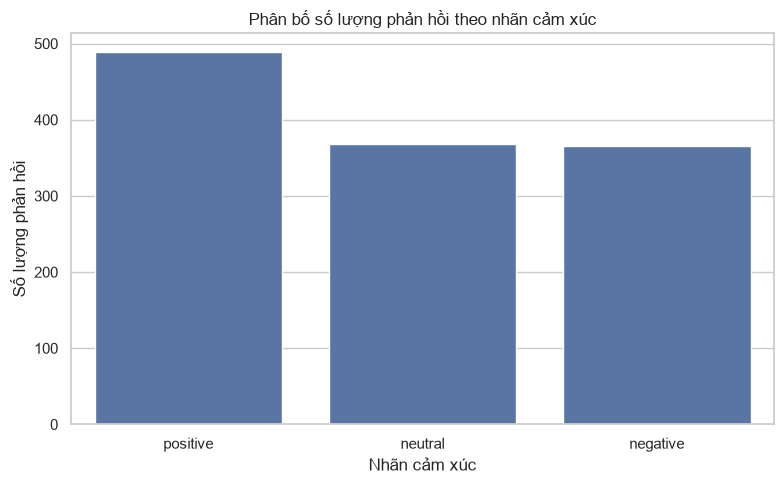

In [10]:
plt.figure(figsize=(8, 5))
order = df[TARGET_COL].value_counts().index

ax = sns.countplot(data=df, x=TARGET_COL, order=order)
ax.set_title("Phân bố số lượng phản hồi theo nhãn cảm xúc")
ax.set_xlabel("Nhãn cảm xúc")
ax.set_ylabel("Số lượng phản hồi")
plt.tight_layout()
plt.show()

### 8.3. Biểu đồ tỷ lệ nhãn cảm xúc

Biểu đồ tròn thể hiện tỷ trọng của từng nhãn trong toàn bộ dữ liệu.

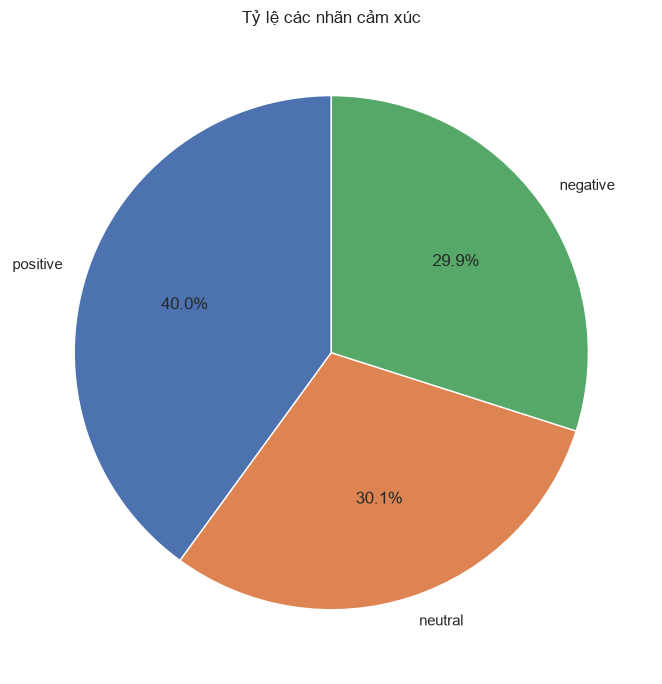

In [11]:
plt.figure(figsize=(7, 7))
sentiment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Tỷ lệ các nhãn cảm xúc")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 9. Phân tích các thuộc tính khác

### 9.1. Số lượng phản hồi theo khoa

Biểu đồ giúp so sánh số lượng phản hồi giữa các khoa. Kết quả chỉ phản ánh số bản ghi trong bộ dữ liệu, không đại diện mặc nhiên cho toàn bộ sinh viên của từng khoa.

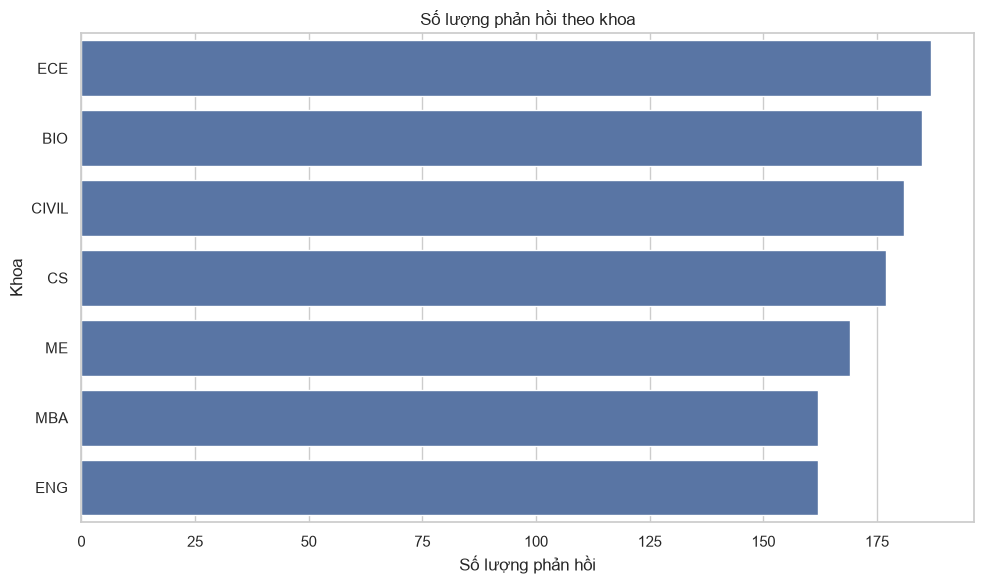

In [12]:
if "department" in df.columns:
    plt.figure(figsize=(10, 6))
    order = df["department"].value_counts().index
    sns.countplot(data=df, y="department", order=order)
    plt.title("Số lượng phản hồi theo khoa")
    plt.xlabel("Số lượng phản hồi")
    plt.ylabel("Khoa")
    plt.tight_layout()
    plt.show()
else:
    print("Không có cột department trong dữ liệu.")

### 9.2. Phân bố loại phản hồi

Thống kê các loại phản hồi để xem nhóm phản hồi nào xuất hiện nhiều hơn trong dữ liệu.

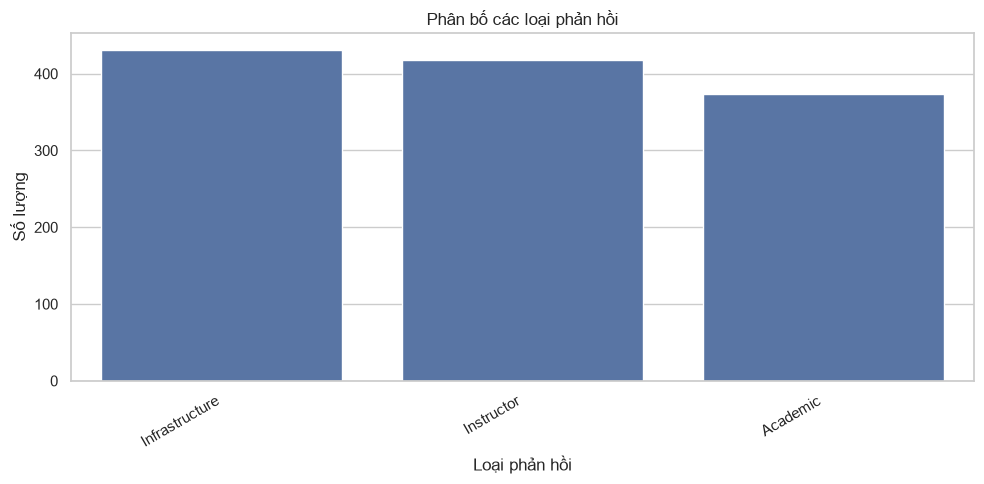

In [13]:
if "feedback_type" in df.columns:
    plt.figure(figsize=(10, 5))
    order = df["feedback_type"].value_counts().index
    sns.countplot(data=df, x="feedback_type", order=order)
    plt.title("Phân bố các loại phản hồi")
    plt.xlabel("Loại phản hồi")
    plt.ylabel("Số lượng")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Không có cột feedback_type trong dữ liệu.")

### 9.3. Mối quan hệ giữa khoa và nhãn cảm xúc

Bảng chéo và biểu đồ cột nhóm cho thấy số lượng từng nhãn cảm xúc theo khoa. Cần lưu ý quy mô dữ liệu giữa các khoa có thể khác nhau.

sentiment_label,negative,neutral,positive
department,,,
BIO,57,50,78
CIVIL,55,49,77
CS,55,54,68
ECE,56,63,68
ENG,53,35,74
MBA,39,61,62
ME,51,56,62


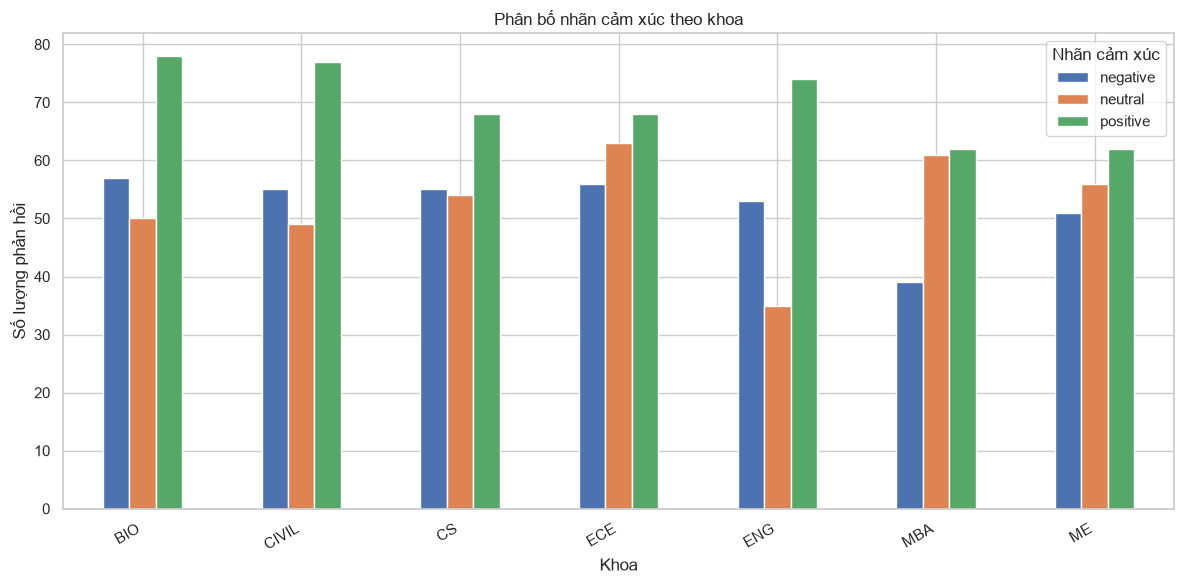

In [14]:
if {"department", TARGET_COL}.issubset(df.columns):
    sentiment_department = pd.crosstab(
        df["department"],
        df[TARGET_COL]
    )
    display(sentiment_department)

    sentiment_department.plot(kind="bar", figsize=(12, 6))
    plt.title("Phân bố nhãn cảm xúc theo khoa")
    plt.xlabel("Khoa")
    plt.ylabel("Số lượng phản hồi")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Nhãn cảm xúc")
    plt.tight_layout()
    plt.show()
else:
    print("Thiếu cột department hoặc sentiment_label.")

## 10. Tổng kết kết quả EDA

Sau khi chạy toàn bộ Notebook, nhóm cần bổ sung nhận xét dựa trên kết quả thực tế hiển thị ở trên:

1. **Quy mô dữ liệu:** Ghi số dòng và số cột của bộ dữ liệu.
2. **Chất lượng dữ liệu:** Nêu số lượng giá trị thiếu và số dòng trùng lặp; nhận xét cột nào cần chú ý.
3. **Phân bố nhãn:** Nêu số lượng và tỷ lệ của từng nhãn cảm xúc; đánh giá mức độ cân bằng lớp.
4. **Đặc điểm văn bản:** Nêu nhận xét sau khi đọc mẫu phản hồi, đặc biệt nếu có văn bản rỗng, bất thường hoặc không rõ ý nghĩa.
5. **Định hướng bước tiếp theo:** Xác định các vấn đề cần xử lý trước khi tiền xử lý văn bản và huấn luyện mô hình.

> Không điền số liệu hoặc kết luận trước khi chạy Notebook và kiểm tra kết quả thực tế. Các phát hiện về dữ liệu bất thường cần được ghi nhận trung thực trong báo cáo.

## 11. Kết luận phần 1

Phần EDA đã cung cấp cái nhìn ban đầu về cấu trúc, chất lượng và phân bố dữ liệu phản hồi sinh viên. Những kết quả này sẽ được sử dụng làm căn cứ cho bước tiền xử lý văn bản, biểu diễn dữ liệu và xây dựng mô hình phân loại cảm xúc ở các phần tiếp theo.